# 01 · Auditoría de datos (EDA)

- Issue: [#6](https://github.com/mudstart/TF_riesgo_de_desercion_estudiantil/issues/6) Auditoría de datos (EDA).
- Rama: `feature/6-auditoria-datos`.
- Depende de: #3 (dataset y ficha de datos) y #4 (momento de intervención y variables permitidas).

**Objetivo.** Auditar la calidad del dataset UCI 697 antes de modelar y detectar problemas que afecten la validez del modelo. Cada sección termina con los hallazgos y la decisión que se deriva. El resumen está en `reports/auditoria_datos.md` y las figuras en `reports/figures/`.

**Alcance.** Este notebook es descriptivo: no entrena modelos ni transforma los datos que usará el pipeline. Las relaciones con el target se analizan sobre todo el dataset, por lo que **no** deben usarse para seleccionar variables ni fijar hiperparámetros (eso se hace solo con la partición de entrenamiento, #7 y #8).

## 0. Configuración y carga

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import chi2_contingency
from sklearn.linear_model import LinearRegression
from sklearn.metrics import roc_auc_score

# Permite ejecutar el notebook desde notebooks/ o desde la raíz del proyecto
PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "src").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT))

from src.config import (
    FEATURES_INGRESO,
    FEATURES_PROHIBIDAS,
    FEATURES_SEM1,
    FEATURES_SENSIBILIDAD,
    TARGET_COL,
)
from src.data import build_target, download_dataset, load_raw

FIG_DIR = PROJECT_ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)


def guardar(fig, nombre):
    """Guarda una figura en reports/figures/."""
    fig.savefig(FIG_DIR / nombre, dpi=120, bbox_inches="tight")

In [2]:
# Descarga (si hace falta) y verifica el SHA-256 antes de leer
df = load_raw(download_dataset())
y = build_target(df)  # 1 = Dropout, 0 = Graduate o Enrolled (decisión 002)
TASA_BASE = y.mean()
print(f"{df.shape[0]} filas x {df.shape[1]} columnas · tasa de Dropout: {TASA_BASE:.1%}")

4424 filas x 37 columnas · tasa de Dropout: 32.1%


### Grupos de variables

**Momento de disponibilidad.** Se importa de `src/config.py`, según la [decisión 001](../docs/decisiones/001_momento_intervencion.md) (#4). La intervención es al ingreso y se modela un solo escenario:

- **Permitidas (`FEATURES_INGRESO`):** 18 variables conocidas al matricularse. Son las únicas del modelo principal.
- **Sensibilidad (`FEATURES_SENSIBILIDAD`):** 6 variables con momento de medición no documentado: las financieras (`Debtor`, `Tuition fees up to date`, `Scholarship holder`) y las macroeconómicas (`Unemployment rate`, `Inflation rate`, `GDP`). Aquí solo se revisan como posible fuga o proxy de cohorte.
- **Prohibidas (`FEATURES_PROHIBIDAS`):** las 12 de rendimiento del 1er y 2do semestre. Solo se auditan como control de calidad.

**Tipo semántico.** Muchas variables categóricas están codificadas como enteros. Se distinguen:

- **Nominales:** códigos sin orden (curso, modo de acceso, nacionalidad, estado civil, titulación y ocupación de los padres, titulación previa).
- **Binarias:** 0/1.
- **Numéricas:** magnitudes u orden real (notas, edad, orden de preferencia, indicadores macroeconómicos, conteos y notas semestrales).

In [3]:
PERMITIDAS = list(FEATURES_INGRESO)
SENSIBILIDAD = list(FEATURES_SENSIBILIDAD)
FINANCIERAS = ["Debtor", "Tuition fees up to date", "Scholarship holder"]
MACRO = ["Unemployment rate", "Inflation rate", "GDP"]
PROHIBIDAS = list(FEATURES_PROHIBIDAS)
SEM1 = list(FEATURES_SEM1)

NOMINALES = [
    "Marital Status", "Application mode", "Course", "Previous qualification",
    "Nacionality", "Mother's qualification", "Father's qualification",
    "Mother's occupation", "Father's occupation",
]
BINARIAS = [
    "Daytime/evening attendance", "Displaced", "Educational special needs",
    "Gender", "International", "Debtor", "Tuition fees up to date", "Scholarship holder",
]
NUMERICAS = [c for c in df.columns if c not in NOMINALES + BINARIAS + [TARGET_COL]]

assert (len(PERMITIDAS), len(SENSIBILIDAD), len(PROHIBIDAS)) == (18, 6, 12)
assert set(FINANCIERAS + MACRO) == set(SENSIBILIDAD)
assert set(PERMITIDAS + SENSIBILIDAD + PROHIBIDAS) == set(df.columns) - {TARGET_COL}
assert len(NOMINALES) + len(BINARIAS) + len(NUMERICAS) == 36

PERM_NOMINALES = [c for c in NOMINALES if c in PERMITIDAS]
PERM_BINARIAS = [c for c in BINARIAS if c in PERMITIDAS]
PERM_NUMERICAS = [c for c in NUMERICAS if c in PERMITIDAS]
print(f"Permitidas: {len(PERM_NOMINALES)} nominales, {len(PERM_BINARIAS)} binarias, "
      f"{len(PERM_NUMERICAS)} numéricas")

Permitidas: 9 nominales, 5 binarias, 4 numéricas


## 1. Tipos de datos

In [4]:
def momento(col):
    if col in PERMITIDAS:
        return "ingreso"
    if col in SENSIBILIDAD:
        return "sensibilidad"
    return "1er sem" if col in SEM1 else "2do sem"


def tipo(col):
    if col in NOMINALES:
        return "nominal"
    return "binaria" if col in BINARIAS else "numérica"


features = df.drop(columns=TARGET_COL)
resumen_tipos = pd.DataFrame({
    "dtype": features.dtypes.astype(str),
    "tipo semántico": [tipo(c) for c in features],
    "momento": [momento(c) for c in features],
    "valores distintos": features.nunique(),
    "mín": features.min(),
    "máx": features.max(),
})
resumen_tipos

,dtype,tipo semántico,momento,valores distintos,mín,máx
Marital Status,int64,nominal,ingreso,6,1.00,6.000000
Application mode,int64,nominal,ingreso,18,1.00,57.000000
Application order,int64,numérica,ingreso,8,0.00,9.000000
Course,int64,nominal,ingreso,17,33.00,9991.000000
Daytime/evening attendance,int64,binaria,ingreso,2,0.00,1.000000
Previous qualification,int64,nominal,ingreso,17,1.00,43.000000
Previous qualification (grade),float64,numérica,ingreso,101,95.00,190.000000
Nacionality,int64,nominal,ingreso,21,1.00,109.000000
Mother's qualification,int64,nominal,ingreso,29,1.00,44.000000
Father's qualification,int64,nominal,ingreso,34,1.00,44.000000


In [5]:
# Las notas semestrales están documentadas en UCI como Integer, pero son decimales
for col in ["Curricular units 1st sem (grade)", "Curricular units 2nd sem (grade)",
            "Previous qualification (grade)", "Admission grade"]:
    no_enteros = (df[col] % 1 != 0).sum()
    print(f"{col:35s} dtype={df[col].dtype}  valores no enteros={no_enteros}")

Curricular units 1st sem (grade)    dtype=float64  valores no enteros=2994
Curricular units 2nd sem (grade)    dtype=float64  valores no enteros=2869
Previous qualification (grade)      dtype=float64  valores no enteros=507
Admission grade                     dtype=float64  valores no enteros=2945


**Hallazgos.** 29 columnas enteras, 7 decimales y el target como texto. Ninguna columna se lee con un tipo erróneo: pandas infiere `float64` para las notas aunque UCI las declare `Integer`. El problema no es de lectura, sino de **semántica**: 9 nominales y 8 binarias están codificadas como enteros y, si se pasan tal cual a un modelo, se interpretan como magnitudes (sección 9).

## 2. Valores nulos y duplicados

In [6]:
nulos = df.isna().sum()
print(f"Nulos totales: {nulos.sum()}  (columnas con nulos: {(nulos > 0).sum()})")
print(f"Filas duplicadas (37 columnas): {df.duplicated().sum()}")
print(f"Filas duplicadas sin el target: {features.duplicated().sum()}")

# Perfiles idénticos en las variables permitidas: el modelo de ingreso no podrá distinguirlos
dup_perm = df[PERMITIDAS].duplicated(keep=False)
grupos = df[dup_perm].groupby(PERMITIDAS, dropna=False)[TARGET_COL].nunique()
print(f"Filas con perfil de ingreso repetido: {dup_perm.sum()} "
      f"({grupos.size} perfiles; {(grupos > 1).sum()} con targets distintos)")

Nulos totales: 0  (columnas con nulos: 0)
Filas duplicadas (37 columnas): 0
Filas duplicadas sin el target: 0
Filas con perfil de ingreso repetido: 0 (0 perfiles; 0 con targets distintos)


**Hallazgos.** Se confirma lo que reportan los autores: 0 nulos y 0 duplicados, tanto en las 37 columnas como sin el target. Tampoco hay dos estudiantes con el mismo perfil en las 18 variables permitidas, así que no existen casos idénticos al ingreso con resultados distintos.

**Decisión.** No se requiere imputación ni deduplicación. Aun así, el pipeline (#8) incluirá un imputador y `handle_unknown` en los codificadores para no fallar con datos nuevos, y las pruebas de contrato (#10) verificarán 0 nulos y 0 duplicados en los datos de entrada.

## 3. Valores fuera de rango

In [7]:
RANGOS = {
    "Age at enrollment": (17, 70),
    "Previous qualification (grade)": (0, 200),
    "Admission grade": (0, 200),
    "Application order": (0, 9),
    "Curricular units 1st sem (grade)": (0, 20),
    "Curricular units 2nd sem (grade)": (0, 20),
}
RANGOS.update({c: (0, 1) for c in BINARIAS})
RANGOS.update({c: (0, np.inf) for c in PROHIBIDAS if c not in RANGOS})

fuera = pd.DataFrame([
    {"variable": c, "rango esperado": f"[{lo}, {hi}]", "mín": df[c].min(), "máx": df[c].max(),
     "fuera de rango": int((~df[c].between(lo, hi)).sum())}
    for c, (lo, hi) in RANGOS.items()
])
print(f"Registros fuera de rango: {fuera['fuera de rango'].sum()}")
fuera[fuera["variable"].isin(["Age at enrollment", "Previous qualification (grade)",
                              "Admission grade", "Application order",
                              "Curricular units 1st sem (grade)", "Curricular units 2nd sem (grade)"])]

Registros fuera de rango: 0


,variable,rango esperado,mín,máx,fuera de rango
0,Age at enrollment,"[17, 70]",17.0,70.000000,0
1,Previous qualification (grade),"[0, 200]",95.0,190.000000,0
2,Admission grade,"[0, 200]",95.0,190.000000,0
3,Application order,"[0, 9]",0.0,9.000000,0
4,Curricular units 1st sem (grade),"[0, 20]",0.0,18.875000,0
5,Curricular units 2nd sem (grade),"[0, 20]",0.0,18.571429,0


In [8]:
# Coherencia entre columnas: no se pueden aprobar más unidades de las inscritas
for sem in ["1st", "2nd"]:
    aprob = df[f"Curricular units {sem} sem (approved)"]
    insc = df[f"Curricular units {sem} sem (enrolled)"]
    print(f"{sem} sem: aprobadas > inscritas en {(aprob > insc).sum()} registros")

print()
print("Application order (0 = primera opción en algunos modos de acceso; 9 = última):")
print(df["Application order"].value_counts().sort_index().to_string())

1st sem: aprobadas > inscritas en 0 registros
2nd sem: aprobadas > inscritas en 0 registros

Application order (0 = primera opción en algunos modos de acceso; 9 = última):
Application order
0       1
1    3026
2     547
3     309
4     249
5     154
6     137
9       1


In [9]:
df[["Age at enrollment", "Previous qualification (grade)", "Admission grade"]].describe().T

,count,mean,std,min,25%,50%,75%,max
Age at enrollment,4424.0,23.265145,7.587816,17.0,19.0,20.0,25.0,70.0
Previous qualification (grade),4424.0,132.613314,13.188332,95.0,125.0,133.1,140.0,190.0
Admission grade,4424.0,126.978119,14.482001,95.0,117.9,126.1,134.8,190.0


**Hallazgos.**

- Ningún valor queda fuera de los rangos documentados: edad 17–70, notas de admisión y de titulación previa entre 95 y 190 (escala 0–200), notas semestrales entre 0 y 18.9 (escala 0–20) y binarias en {0, 1}. En ningún semestre hay más unidades aprobadas que inscritas.
- La edad es muy asimétrica: mediana 20, media 23.3 y cola larga hasta 70. No son errores: son estudiantes adultos, un subgrupo real (sección 6).
- `Application order` va de 1 a 6 salvo dos registros aislados (un 0 y un 9). Son plausibles según el diccionario (0 = primera opción, 9 = última), pero únicos.

**Decisión.** No se eliminan ni recortan valores extremos: son plausibles y describen subgrupos reales. Las pruebas de contrato (#10) usarán estos rangos como validación de entrada.

## 4. Casos especiales: unidades inscritas en 0 y notas en 0

Estas variables son **prohibidas** (decisión 001) y no entran en ningún modelo. Se auditan como control de calidad del dataset y porque muestran el tamaño de la tentación de fuga.

In [10]:
insc1 = df["Curricular units 1st sem (enrolled)"]
sin_insc = df[insc1 == 0]
print(f"Estudiantes con 0 unidades inscritas en el 1er semestre: {len(sin_insc)}")
print(f"  ... de ellos, también 0 en el 2do: {(sin_insc['Curricular units 2nd sem (enrolled)'] == 0).sum()}")
print(f"  ... con unidades acreditadas (credited) > 0 en el 1er sem: "
      f"{(sin_insc['Curricular units 1st sem (credited)'] > 0).sum()}")
print(f"  ... con nota del 1er sem = 0: {(sin_insc['Curricular units 1st sem (grade)'] == 0).sum()}")
print()
print("Target de este grupo frente al total:")
pd.DataFrame({
    "sin unidades inscritas": sin_insc[TARGET_COL].value_counts(normalize=True),
    "total": df[TARGET_COL].value_counts(normalize=True),
}).round(3)

Estudiantes con 0 unidades inscritas en el 1er semestre: 180
  ... de ellos, también 0 en el 2do: 180
  ... con unidades acreditadas (credited) > 0 en el 1er sem: 0
  ... con nota del 1er sem = 0: 180

Target de este grupo frente al total:


,sin unidades inscritas,total
Target,,
Dropout,0.428,0.321
Enrolled,0.156,0.179
Graduate,0.417,0.499


In [11]:
curso = sin_insc["Course"].value_counts()
print("Curso de los estudiantes sin unidades inscritas:")
print(curso.to_string())
total_171 = (df["Course"] == 171).sum()
print(f"Estudiantes del curso 171 (Animation and Multimedia Design): {total_171}; "
      f"sin unidades inscritas: {curso.get(171, 0)} ({curso.get(171, 0) / total_171:.0%})")

Curso de los estudiantes sin unidades inscritas:
Course
171    180
Estudiantes del curso 171 (Animation and Multimedia Design): 215; sin unidades inscritas: 180 (84%)


In [12]:
filas = []
for sem in ["1st", "2nd"]:
    nota = df[f"Curricular units {sem} sem (grade)"]
    aprob = df[f"Curricular units {sem} sem (approved)"]
    insc = df[f"Curricular units {sem} sem (enrolled)"]
    filas.append({
        "semestre": sem,
        "nota = 0": int((nota == 0).sum()),
        "nota = 0 y aprobadas = 0": int(((nota == 0) & (aprob == 0)).sum()),
        "aprobadas = 0 y nota > 0": int(((aprob == 0) & (nota > 0)).sum()),
        "nota = 0 sin unidades inscritas": int(((nota == 0) & (insc == 0)).sum()),
        "% Dropout si nota = 0": round(y[nota == 0].mean() * 100, 1),
    })
pd.DataFrame(filas)

,semestre,nota = 0,nota = 0 y aprobadas = 0,aprobadas = 0 y nota > 0,nota = 0 sin unidades inscritas,% Dropout si nota = 0
0,1st,718,718,0,180,79.4
1,2nd,870,870,0,180,83.6


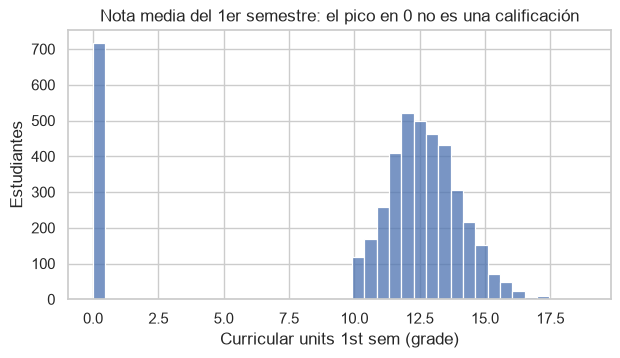

In [13]:
fig, ax = plt.subplots(figsize=(7, 3.5))
sns.histplot(df["Curricular units 1st sem (grade)"], bins=40, ax=ax)
ax.set(title="Nota media del 1er semestre: el pico en 0 no es una calificación",
       xlabel="Curricular units 1st sem (grade)", ylabel="Estudiantes")
guardar(fig, "01_auditoria_nota_cero.png")
plt.show()

**Hallazgos.**

- Hay 180 estudiantes con 0 unidades inscritas en el 1er semestre. Todos tienen también 0 en el 2do semestre, 0 unidades acreditadas y nota 0, aunque no cursaron nada: es un valor "no aplica", no una nota.
- **Los 180 pertenecen al curso 171 (Animation and Multimedia Design)**: son el 84 % de ese curso (180 de 215). Además, el 41.7 % de ellos figura como Graduate sin haber inscrito una sola unidad en el primer año. Esto no describe el comportamiento de los estudiantes: indica que **faltan los registros semestrales de ese curso** (probablemente se gestionaban en otro sistema o el curso empezó a registrarse más tarde).
- Una nota semestral de 0 coincide **siempre** con 0 unidades aprobadas (718 casos en el 1er semestre y 870 en el 2do): la nota es el promedio de las unidades aprobadas y 0 significa "sin notas". Tratarla como numérica crea una discontinuidad artificial (pico en 0, figura `01_auditoria_nota_cero.png`).
- Con nota 0 la tasa de Dropout es 79.4 % (1er sem) y 83.6 % (2do sem), frente a 32.1 % de base: es la señal más fuerte del dataset, y por eso la tentación de fuga.

**Decisión.**

- Estas variables son prohibidas, así que el problema del curso 171 no afecta a los modelos.
- Documentar el hallazgo del curso 171 en la ficha de datos como limitación adicional: cualquier análisis que use las variables semestrales (por ejemplo, una comparación con la literatura) debe tratar esos 180 registros como faltantes, no como ceros, y la nota 0 como "sin notas".
- Considerar el curso 171 en el análisis de errores (#14): es el curso con datos menos fiables.

## 5. Distribución de la variable objetivo

In [14]:
dist = pd.DataFrame({
    "estudiantes": df[TARGET_COL].value_counts(),
    "%": (df[TARGET_COL].value_counts(normalize=True) * 100).round(1),
})
print(dist.to_string())
print(f"\nBinario (decisión 002): Dropout = {y.sum()} ({y.mean():.1%}), "
      f"No-Dropout = {(1 - y).sum()} ({1 - y.mean():.1%})")
print(f"Razón de desbalance No-Dropout : Dropout = {(1 - y).sum() / y.sum():.2f} : 1")

          estudiantes     %
Target                     
Graduate         2209  49.9
Dropout          1421  32.1
Enrolled          794  17.9

Binario (decisión 002): Dropout = 1421 (32.1%), No-Dropout = 3003 (67.9%)
Razón de desbalance No-Dropout : Dropout = 2.11 : 1


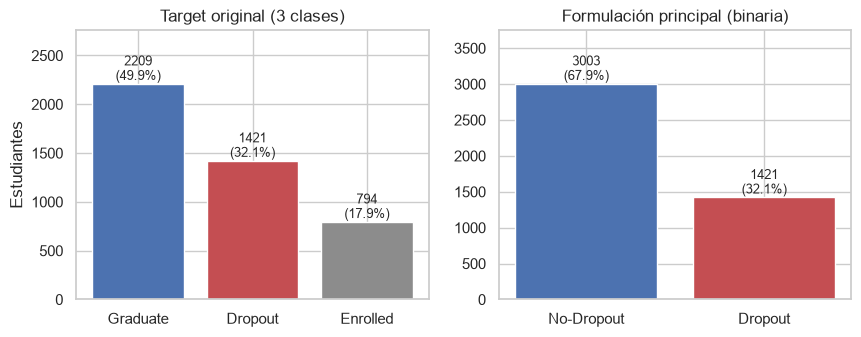

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
orden = ["Graduate", "Dropout", "Enrolled"]
colores = {"Graduate": "#4C72B0", "Dropout": "#C44E52", "Enrolled": "#8C8C8C"}
conteo = df[TARGET_COL].value_counts().reindex(orden)
axes[0].bar(orden, conteo, color=[colores[c] for c in orden])
axes[0].set(title="Target original (3 clases)", ylabel="Estudiantes")
for i, v in enumerate(conteo):
    axes[0].text(i, v, f"{v}\n({v / len(df):.1%})", ha="center", va="bottom", fontsize=9)

binario = y.map({1: "Dropout", 0: "No-Dropout"}).value_counts().reindex(["No-Dropout", "Dropout"])
axes[1].bar(binario.index, binario, color=["#4C72B0", "#C44E52"])
axes[1].set(title="Formulación principal (binaria)")
for i, v in enumerate(binario):
    axes[1].text(i, v, f"{v}\n({v / len(df):.1%})", ha="center", va="bottom", fontsize=9)
for ax in axes:
    ax.set_ylim(0, conteo.max() * 1.25 if ax is axes[0] else binario.max() * 1.25)
guardar(fig, "02_auditoria_target.png")
plt.show()

**Hallazgos.** Graduate 49.9 %, Dropout 32.1 % y Enrolled 17.9 %. En la formulación binaria el desbalance es moderado (≈ 2.1 : 1). La exactitud (*accuracy*) no sirve como métrica: un modelo que nunca predice Dropout acierta 67.9 %.

**Decisión.** Partición y validación cruzada estratificadas por la clase original de 3 valores (#7); métricas F1-macro y recall de Dropout con su precisión (decisión 002); evaluar `class_weight="balanced"` y el ajuste del umbral en los modelos (#9, #11, #12) antes que remuestreo sintético.

## 6. Distribuciones univariadas de variables clave

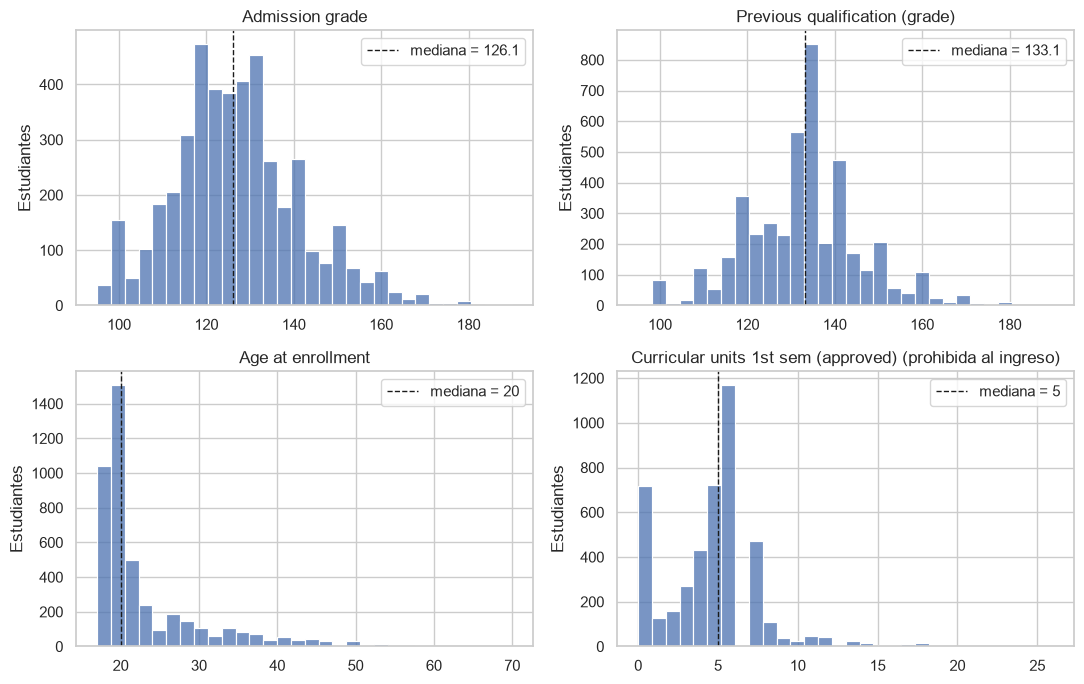

,mean,median,std,min,max,skew
Admission grade,126.98,126.1,14.48,95.0,190.0,0.53
Previous qualification (grade),132.61,133.1,13.19,95.0,190.0,0.31
Age at enrollment,23.27,20.0,7.59,17.0,70.0,2.05
Curricular units 1st sem (approved),4.71,5.0,3.09,0.0,26.0,0.77


In [16]:
clave = ["Admission grade", "Previous qualification (grade)", "Age at enrollment",
         "Curricular units 1st sem (approved)"]
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, col in zip(axes.ravel(), clave):
    sns.histplot(df[col], bins=30, ax=ax)
    ax.axvline(df[col].median(), color="k", ls="--", lw=1, label=f"mediana = {df[col].median():g}")
    etiqueta = " (prohibida al ingreso)" if col in PROHIBIDAS else ""
    ax.set(title=col + etiqueta, xlabel="", ylabel="Estudiantes")
    ax.legend()
fig.tight_layout()
guardar(fig, "03_auditoria_univariadas.png")
plt.show()

df[clave].agg(["mean", "median", "std", "min", "max", "skew"]).T.round(2)

In [17]:
edad = df["Age at enrollment"]
print(f"Ingresan con 25 años o más: {(edad >= 25).sum()} ({(edad >= 25).mean():.1%})")
print(f"Ingresan con 35 años o más: {(edad >= 35).sum()} ({(edad >= 35).mean():.1%})")

Ingresan con 25 años o más: 1138 (25.7%)
Ingresan con 35 años o más: 441 (10.0%)


**Hallazgos.**

- `Admission grade` (mediana 126.1) y `Previous qualification (grade)` (mediana 133.1) son aproximadamente simétricas (asimetría 0.53 y 0.31).
- `Age at enrollment` tiene asimetría fuerte a la derecha (2.05): la mediana es 20 años, pero el 25.7 % ingresa con 25 o más y el 10 % con 35 o más.
- `Curricular units 1st sem (approved)` (mediana 5) tiene un pico en 0, coherente con la sección 4.

**Decisión.** Escalar las numéricas para la regresión logística (#9). Evaluar transformación logarítmica o tramos de edad solo si mejora la validación cruzada; los árboles (#11, #12) no la necesitan.

## 7. Relación de las variables con el target

Solo variables **permitidas** (18). Las 6 de sensibilidad se revisan aparte como verificación de fuga, y las prohibidas no se analizan.

- **Numéricas:** AUC univariada para separar Dropout (0.5 = sin señal). Se reporta `max(AUC, 1 − AUC)` y la dirección.
- **Nominales y binarias:** V de Cramér con corrección de sesgo (0 = independencia, 1 = asociación perfecta).

> Medidas descriptivas sobre todo el dataset: orientan la interpretación, no la selección de variables.

In [18]:
def cramers_v(a, b):
    """V de Cramér con corrección de sesgo (Bergsma, 2013)."""
    tabla = pd.crosstab(a, b)
    chi2 = chi2_contingency(tabla, correction=False)[0]
    n = tabla.to_numpy().sum()
    r, k = tabla.shape
    phi2 = max(0.0, chi2 / n - (k - 1) * (r - 1) / (n - 1))
    r_c = r - (r - 1) ** 2 / (n - 1)
    k_c = k - (k - 1) ** 2 / (n - 1)
    denom = min(k_c - 1, r_c - 1)
    return np.sqrt(phi2 / denom) if denom > 0 else 0.0


filas = []
for col in PERM_NUMERICAS:
    auc = roc_auc_score(y, df[col])
    filas.append({
        "variable": col,
        "AUC": round(max(auc, 1 - auc), 3),
        "Dropout asociado a valores": "altos" if auc > 0.5 else "bajos",
        "media Dropout": round(df.loc[y == 1, col].mean(), 2),
        "media No-Dropout": round(df.loc[y == 0, col].mean(), 2),
    })
rel_num = pd.DataFrame(filas).sort_values("AUC", ascending=False)
rel_num

,variable,AUC,Dropout asociado a valores,media Dropout,media No-Dropout
3,Age at enrollment,0.671,altos,26.07,21.94
2,Admission grade,0.561,bajos,124.96,127.93
1,Previous qualification (grade),0.549,bajos,131.11,133.32
0,Application order,0.542,bajos,1.59,1.79


In [19]:
rel_cat = pd.DataFrame([
    {"variable": col, "tipo": tipo(col), "categorías": df[col].nunique(),
     "V de Cramér": round(cramers_v(df[col], y), 3)}
    for col in PERM_NOMINALES + PERM_BINARIAS
]).sort_values("V de Cramér", ascending=False)
rel_cat

,variable,tipo,categorías,V de Cramér
1,Application mode,nominal,18,0.294
2,Course,nominal,17,0.253
3,Previous qualification,nominal,17,0.205
12,Gender,binaria,2,0.203
7,Mother's occupation,nominal,32,0.197
5,Mother's qualification,nominal,29,0.189
6,Father's qualification,nominal,34,0.183
8,Father's occupation,nominal,46,0.167
0,Marital Status,nominal,6,0.111
10,Displaced,binaria,2,0.106


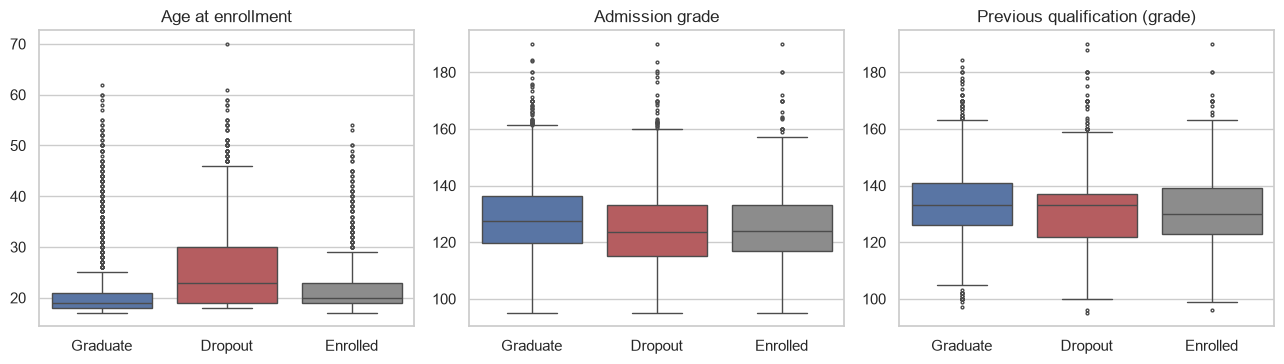

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, col in zip(axes, ["Age at enrollment", "Admission grade", "Previous qualification (grade)"]):
    sns.boxplot(data=df, x=TARGET_COL, y=col, order=orden, hue=TARGET_COL,
                palette=colores, legend=False, ax=ax, fliersize=2)
    ax.set(title=col, xlabel="", ylabel="")
fig.tight_layout()
guardar(fig, "04_auditoria_numericas_vs_target.png")
plt.show()

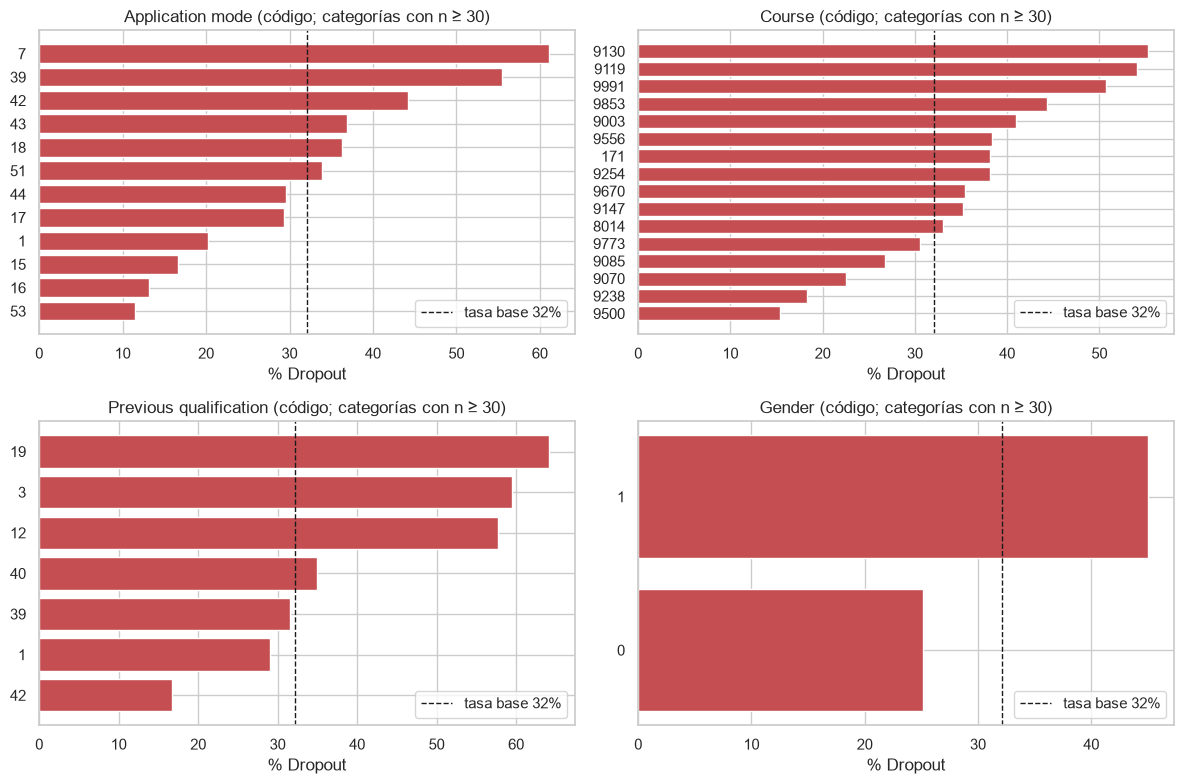

In [21]:
def tasa_por_categoria(col, minimo=30):
    """Tasa de Dropout por categoría (solo categorías con al menos `minimo` estudiantes)."""
    t = df.groupby(col).agg(n=(TARGET_COL, "size"))
    t["% Dropout"] = y.groupby(df[col]).mean() * 100
    return t[t["n"] >= minimo].sort_values("% Dropout")


top_cat = rel_cat["variable"].head(4).tolist()
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, col in zip(axes.ravel(), top_cat):
    t = tasa_por_categoria(col)
    ax.barh(t.index.astype(str), t["% Dropout"], color="#C44E52")
    ax.axvline(TASA_BASE * 100, color="k", ls="--", lw=1, label=f"tasa base {TASA_BASE:.0%}")
    ax.set(title=f"{col} (código; categorías con n ≥ 30)", xlabel="% Dropout")
    ax.legend(loc="lower right")
fig.tight_layout()
guardar(fig, "05_auditoria_categoricas_vs_target.png")
plt.show()

### Variables de sensibilidad: verificación de fuga

In [22]:
fuga = []
for col in FINANCIERAS:
    for valor, n in df[col].value_counts().sort_index().items():
        fuga.append({"variable": col, "valor": valor, "n": n,
                     "% Dropout": round(y[df[col] == valor].mean() * 100, 1)})
fuga = pd.DataFrame(fuga)
print(f"Tasa base de Dropout: {TASA_BASE:.1%}")
print("V de Cramér con el target:",
      {c: round(cramers_v(df[c], y), 3) for c in FINANCIERAS})
fuga

Tasa base de Dropout: 32.1%
V de Cramér con el target: {'Debtor': np.float64(0.229), 'Tuition fees up to date': np.float64(0.429), 'Scholarship holder': np.float64(0.245)}


,variable,valor,n,% Dropout
0,Debtor,0,3921,28.3
1,Debtor,1,503,62.0
2,Tuition fees up to date,0,528,86.6
3,Tuition fees up to date,1,3896,24.7
4,Scholarship holder,0,3325,38.7
5,Scholarship holder,1,1099,12.2


In [23]:
# Macroeconómicas: AUC univariada, para comparar con las permitidas
pd.DataFrame([
    {"variable": c, "AUC": round(max(a := roc_auc_score(y, df[c]), 1 - a), 3)}
    for c in MACRO
])

,variable,AUC
0,Unemployment rate,0.506
1,Inflation rate,0.514
2,GDP,0.535


**Hallazgos.**

- Entre las variables permitidas la señal es **moderada**. La numérica más informativa es la edad al ingreso (AUC 0.67: más edad, más Dropout); las notas de admisión y previa apenas separan (AUC 0.56 y 0.55).
- Entre las categóricas destacan `Application mode` (V = 0.29), `Course` (0.25), `Previous qualification` (0.21) y `Gender` (0.20: 45.1 % de Dropout en hombres frente a 25.1 % en mujeres). Las ocupaciones y titulaciones de los padres muestran asociaciones de 0.17–0.20, en parte infladas por sus muchas categorías pequeñas.
- `Nacionality`, `International` y `Educational special needs` no muestran asociación con Dropout (V ≈ 0).
- Las variables financieras tienen asociaciones más fuertes que cualquier variable permitida: con `Tuition fees up to date = 0` el Dropout es 86.6 % (V = 0.43), con `Debtor = 1` es 62.0 % y con `Scholarship holder = 1` baja a 12.2 %. Este patrón es compatible con que se registraran durante la carrera, es decir, con fuga.
- Las macroeconómicas casi no separan Dropout (AUC ≤ 0.54), lo que coincide con la decisión 001: excluirlas no tiene costo.

**Decisión.** Se confirma la decisión 001: el modelo principal usa solo las 18 permitidas y debe esperarse un desempeño modesto, que es el precio de no usar información futura. Las 6 de sensibilidad solo entran en el análisis de sensibilidad, que debe reportar el salto que producen las financieras.

## 8. Correlaciones y multicolinealidad

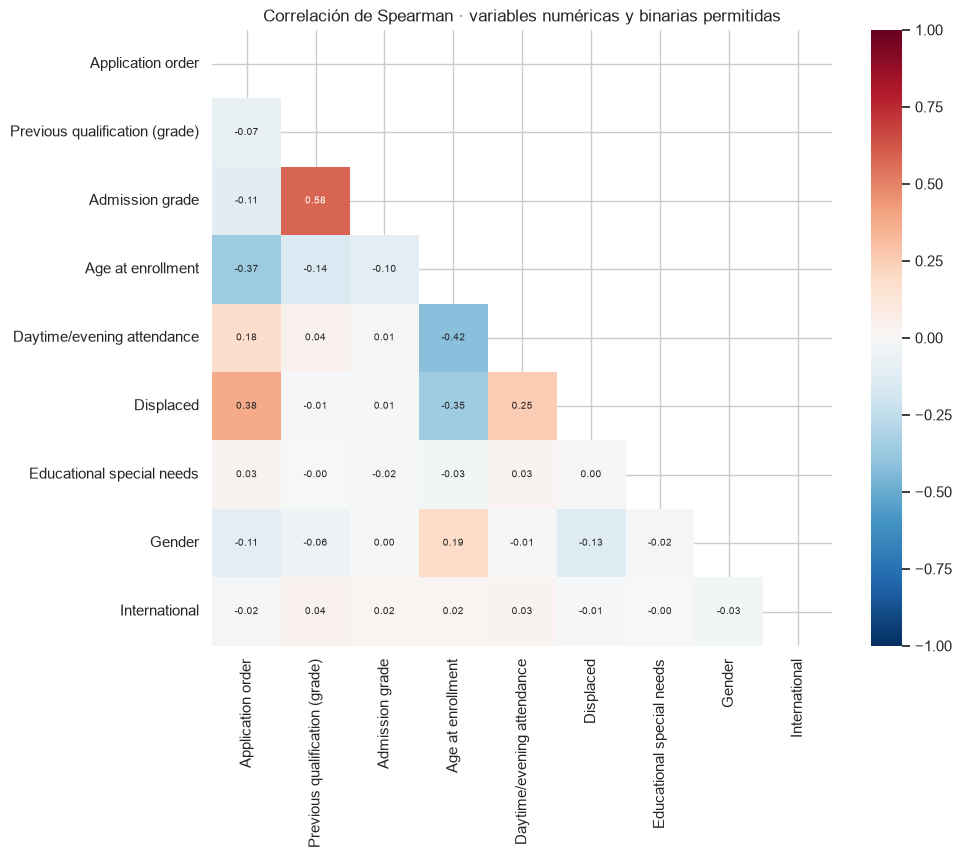

In [24]:
cols_corr = PERM_NUMERICAS + PERM_BINARIAS
corr = df[cols_corr].corr(method="spearman")

fig, ax = plt.subplots(figsize=(10, 8))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            annot=True, fmt=".2f", annot_kws={"size": 7}, ax=ax)
ax.set_title("Correlación de Spearman · variables numéricas y binarias permitidas")
guardar(fig, "06_auditoria_correlaciones.png")
plt.show()

In [25]:
pares = (corr.where(np.triu(np.ones_like(corr, dtype=bool), k=1)).stack()
         .rename("rho").reset_index())
pares = pares[pares["rho"].abs() >= 0.4].sort_values("rho", key=abs, ascending=False)
pares.round(3)

,level_0,level_1,rho
11,Previous qualification (grade),Admission grade,0.585
31,Age at enrollment,Daytime/evening attendance,-0.420


In [26]:
def vif(X):
    """Factor de inflación de la varianza: 1 / (1 - R²) de cada columna sobre las demás."""
    res = {}
    for col in X.columns:
        otras = X.drop(columns=col)
        r2 = LinearRegression().fit(otras, X[col]).score(otras, X[col])
        res[col] = np.inf if r2 >= 1 else 1 / (1 - r2)
    return pd.Series(res, name="VIF").sort_values(ascending=False).round(2)


vif(df[PERM_NUMERICAS + PERM_BINARIAS]).to_frame()

,VIF
Previous qualification (grade),1.54
Admission grade,1.52
Age at enrollment,1.46
Daytime/evening attendance,1.29
Displaced,1.26
Application order,1.18
Gender,1.04
International,1.00
Educational special needs,1.00


In [27]:
# Asociación entre nominales y binarias permitidas (V de Cramér)
cats = PERM_NOMINALES + PERM_BINARIAS
assoc = pd.DataFrame(
    [{"a": a, "b": b, "V de Cramér": round(cramers_v(df[a], df[b]), 3)}
     for i, a in enumerate(cats) for b in cats[i + 1:]]
)
assoc[assoc["V de Cramér"] >= 0.4].sort_values("V de Cramér", ascending=False)

,a,b,V de Cramér
31,Course,Daytime/evening attendance,0.998
54,Nacionality,International,0.998
70,Mother's occupation,Father's occupation,0.571
24,Application mode,International,0.530
55,Mother's qualification,Father's qualification,0.431
34,Course,Gender,0.424
14,Application mode,Previous qualification,0.412
21,Application mode,Displaced,0.411
20,Application mode,Daytime/evening attendance,0.410


In [28]:
macro = df[["Unemployment rate", "Inflation rate", "GDP"]]
print(f"Combinaciones distintas de (desempleo, inflación, PIB): {len(macro.drop_duplicates())}")
cohortes = macro.value_counts().rename("estudiantes").reset_index()
cohortes["% Dropout"] = [
    round(y[(macro == fila.values).all(axis=1)].mean() * 100, 1)
    for _, fila in cohortes[macro.columns].iterrows()
]
cohortes

Combinaciones distintas de (desempleo, inflación, PIB): 10


,Unemployment rate,Inflation rate,GDP,estudiantes,% Dropout
0,7.6,2.6,0.32,571,35.4
1,9.4,-0.8,-3.12,533,32.6
2,10.8,1.4,1.74,525,34.7
3,12.4,0.5,1.79,445,24.0
4,12.7,3.7,-1.70,419,33.7
5,11.1,0.6,2.02,414,28.3
6,15.5,2.8,-4.06,397,35.0
7,13.9,-0.3,0.79,390,30.3
8,8.9,1.4,3.51,368,27.7
9,16.2,0.3,-0.92,362,38.4


**Hallazgos.**

- **Dos variables son redundantes de forma exacta** (V ≈ 1.0):
  - `International` = 1 si y solo si `Nacionality` ≠ 1 (portuguesa).
  - `Daytime/evening attendance` queda determinada por `Course`: los únicos cursos nocturnos son 8014 (Social Service, evening) y 9991 (Management, evening).
  Con `Course` y `Nacionality` en one-hot, ambas son combinaciones lineales exactas de otras columnas.
- Entre las numéricas no hay multicolinealidad preocupante: la mayor correlación es `Admission grade` ~ `Previous qualification (grade)` (ρ = 0.58) y todos los VIF son < 1.6. (El VIF no detecta las dos redundancias anteriores porque involucran variables nominales.)
- Asociaciones moderadas entre categóricas: ocupaciones de madre y padre (V = 0.57), titulaciones de madre y padre (0.43), `Application mode` con `International`, `Previous qualification`, `Displaced` y el régimen de asistencia (≈ 0.41–0.53), y `Course` con `Gender` (0.42).
- Las tres variables macroeconómicas (sensibilidad) solo toman 10 combinaciones, con tasas de Dropout entre 24.0 % y 38.4 %: identifican la cohorte de ingreso. Esto refuerza su exclusión del modelo principal (decisión 001).

**Decisión propuesta** (a formalizar en la decisión de preprocesamiento de #8, porque cambia las columnas que entran al modelo):

- Excluir `International` y `Daytime/evening attendance` de las columnas del modelo: no aportan información que no esté en `Nacionality` y `Course`. Se conservan para describir subgrupos.
- Regularización en la logística (#9). Los árboles (#11, #12) toleran la colinealidad, pero la importancia de variables se reparte entre variables asociadas: interpretarla por grupos (#14).

## 9. Variables categóricas codificadas como números

In [29]:
nom = pd.DataFrame([
    {"variable": col, "momento": momento(col), "categorías": df[col].nunique(),
     "códigos (mín–máx)": f"{df[col].min()}–{df[col].max()}"}
    for col in NOMINALES
]).sort_values("categorías", ascending=False)
nom

,variable,momento,categorías,códigos (mín–máx)
8,Father's occupation,ingreso,46,0–195
6,Father's qualification,ingreso,34,1–44
7,Mother's occupation,ingreso,32,0–194
5,Mother's qualification,ingreso,29,1–44
4,Nacionality,ingreso,21,1–109
1,Application mode,ingreso,18,1–57
3,Previous qualification,ingreso,17,1–43
2,Course,ingreso,17,33–9991
0,Marital Status,ingreso,6,1–6


In [30]:
# Si se tratara como continua, el modelo supondría que el curso 9991 es "mayor" que el 33.
# La tasa de Dropout no sigue el orden de los códigos:
t = tasa_por_categoria("Course", minimo=1).sort_index()
rho = pd.Series(t.index, index=t.index).corr(t["% Dropout"], method="spearman")
print(f"Spearman entre código de curso y % Dropout: {rho:.2f}")
t.round(1)

Spearman entre código de curso y % Dropout: -0.08


,n,% Dropout
Course,,
33,12,66.7
171,215,38.1
8014,215,33.0
9003,210,41.0
9070,226,22.6
9085,337,26.7
9119,170,54.1
9130,141,55.3
9147,380,35.3


**Hallazgos.** Las 9 variables nominales (todas permitidas) están codificadas como enteros sin orden: códigos de curso de 33 a 9991, ocupaciones de 0 a 195 con hasta 46 códigos. La tasa de Dropout por curso va de 15.4 % (9500, Nursing) a 66.7 % (33, n = 12) sin relación con el código (ρ de Spearman = −0.08), así que tratarlas como continuas impone una relación lineal sin sentido. Las 8 binarias ya están en 0/1 y pueden usarse tal cual.

**Decisión propuesta** (a formalizar en la decisión de preprocesamiento de #8): `OneHotEncoder` para las nominales, binarias sin transformar y `StandardScaler` para las numéricas, dentro de un `ColumnTransformer` ajustado solo con entrenamiento. Las pruebas (#10) verificarán que ninguna nominal entra al modelo como numérica.

## 10. Categorías con muy pocos registros

In [31]:
UMBRAL = 10
raras = []
for col in NOMINALES:
    vc = df[col].value_counts()
    raras.append({
        "variable": col,
        "momento": momento(col),
        "categorías": len(vc),
        f"categorías con < {UMBRAL}": int((vc < UMBRAL).sum()),
        f"filas afectadas (< {UMBRAL})": int(vc[vc < UMBRAL].sum()),
        "categorías con < 30": int((vc < 30).sum()),
        f"categorías tras agrupar": int((vc >= UMBRAL).sum()) + int((vc < UMBRAL).any()),
    })
raras = pd.DataFrame(raras).sort_values("categorías", ascending=False)
raras

,variable,momento,categorías,categorías con < 10,filas afectadas (< 10),categorías con < 30,categorías tras agrupar
8,Father's occupation,ingreso,46,32,78,34,15
6,Father's qualification,ingreso,34,22,54,25,13
7,Mother's occupation,ingreso,32,18,62,21,15
5,Mother's qualification,ingreso,29,19,68,20,11
4,Nacionality,ingreso,21,16,32,19,6
1,Application mode,ingreso,18,4,6,6,15
3,Previous qualification,ingreso,17,7,29,10,11
2,Course,ingreso,17,0,0,1,17
0,Marital Status,ingreso,6,2,10,3,5


In [32]:
# Ejemplo: nacionalidad (1 = portuguesa)
df["Nacionality"].value_counts().to_frame("estudiantes").T

Nacionality,1,41,26,6,22,24,103,11,100,62,25,21,101,2,105,13,32,109,108,14,17
estudiantes,4314,38,14,13,13,5,3,3,3,2,2,2,2,2,2,1,1,1,1,1,1


**Hallazgos.** Las variables de alta cardinalidad concentran casi todos sus registros en pocas categorías:

- Ocupación del padre: 32 de 46 categorías tienen menos de 10 estudiantes (78 filas); de la madre, 18 de 32 (62 filas).
- Titulación del padre: 22 de 34 (54 filas); de la madre, 19 de 29 (68 filas).
- Nacionalidad: 16 de 21 (32 filas). El 97.5 % es portugués y las otras 20 nacionalidades suman 110 estudiantes.
- Titulación previa: 7 de 17; modo de acceso: 4 de 18; estado civil: 2 de 6. `Course` no tiene categorías con menos de 10 (el mínimo es el curso 33, con 12). Con one-hot sin agrupar, esas columnas casi vacías generan sobreajuste y, en validación cruzada, categorías que aparecen en validación y no en entrenamiento.

**Decisión propuesta** (a formalizar en la decisión de preprocesamiento de #8):

- Agrupar en "Otros" las categorías con **menos de 10 registros** (ejemplo: nacionalidades con < 10 estudiantes).
- La agrupación se aprende **solo con la partición de entrenamiento**: `OneHotEncoder(min_frequency=10, handle_unknown="infrequent_if_exist")` dentro del pipeline (#8). Agrupar con todo el dataset antes de partir sería una fuga leve.
- Si tras agrupar sigue habiendo categorías inestables, evaluar umbral 30 en validación cruzada.

## 11. Variables sensibles

In [33]:
sens = pd.DataFrame({
    "Género": df["Gender"].map({1: "Hombre", 0: "Mujer"}),
    "Edad al ingreso": pd.cut(df["Age at enrollment"], [16, 19, 24, 34, 100],
                              labels=["17–19", "20–24", "25–34", "35+"]),
    "Nacionalidad": np.where(df["Nacionality"] == 1, "Portuguesa", "Otra"),
    "Becario (sensibilidad)": df["Scholarship holder"].map({1: "Sí", 0: "No"}),
    "Necesidades educativas especiales": df["Educational special needs"].map({1: "Sí", 0: "No"}),
    "Estado civil": np.where(df["Marital Status"] == 1, "Soltero/a", "Otro"),
})

tablas = []
for col in sens:
    g = pd.DataFrame({"n": sens[col].value_counts(sort=False)})
    g["% estudiantes"] = (g["n"] / len(df) * 100).round(1)
    g["% Dropout"] = (y.groupby(sens[col], observed=True).mean() * 100).round(1)
    g.index = pd.MultiIndex.from_product([[col], g.index.astype(str)])
    tablas.append(g)
tabla_sens = pd.concat(tablas)
tabla_sens

n  % estudiantes  % Dropout
Género                            Hombre      1556           35.2       45.1
                                  Mujer       2868           64.8       25.1
Edad al ingreso                   17–19       1952           44.1       21.0
                                  20–24       1334           30.2       28.6
                                  25–34        697           15.8       56.5
                                  35+          441           10.0       53.7
Nacionalidad                      Portuguesa  4314           97.5       32.2
                                  Otra         110            2.5       29.1
Becario (sensibilidad)            No          3325           75.2       38.7
                                  Sí          1099           24.8       12.2
Necesidades educativas especiales No          4373           98.8       32.1
                                  Sí            51            1.2       33.3
Estado civil                      Soltero/a   3919           88.6       30.2
                                  Otro         505           11.4       46.9

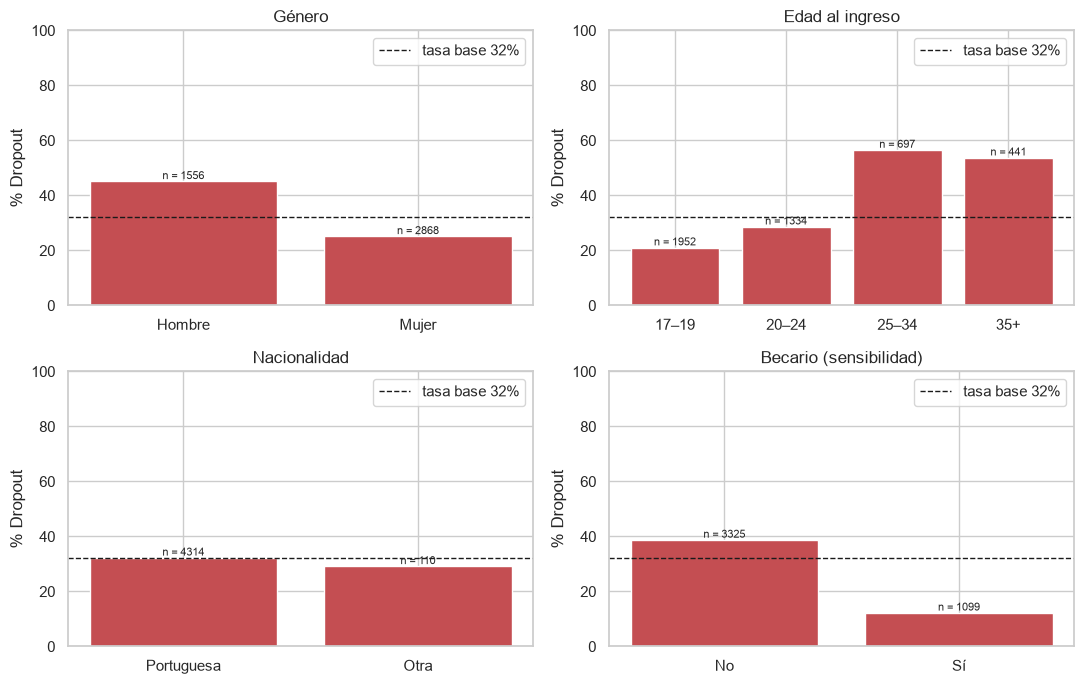

In [34]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, col in zip(axes.ravel(), ["Género", "Edad al ingreso", "Nacionalidad", "Becario (sensibilidad)"]):
    t = tabla_sens.loc[col]
    barras = ax.bar(t.index, t["% Dropout"], color="#C44E52")
    ax.axhline(TASA_BASE * 100, color="k", ls="--", lw=1, label=f"tasa base {TASA_BASE:.0%}")
    ax.bar_label(barras, labels=[f"n = {n}" for n in t["n"]], fontsize=8)
    ax.set(title=col, ylabel="% Dropout", ylim=(0, 100))
    ax.legend(loc="upper right")
fig.tight_layout()
guardar(fig, "07_auditoria_sensibles.png")
plt.show()

**Hallazgos.**

- **Género:** 35.2 % hombres y 64.8 % mujeres. Dropout: 45.1 % en hombres frente a 25.1 % en mujeres. Parte de esa diferencia puede deberse al curso (V de Cramér `Course`–`Gender` = 0.42: hay cursos muy feminizados, como Enfermería, con baja deserción).
- **Edad:** Dropout de 21.0 % (17–19 años), 28.6 % (20–24), 56.5 % (25–34) y 53.7 % (35+). Los estudiantes de 25 años o más (25.7 %) abandonan más del doble que los de 17–19.
- **Nacionalidad:** 110 estudiantes no portugueses (2.5 %), con Dropout de 29.1 % frente a 32.2 %: sin diferencia relevante, pero con un grupo tan pequeño cualquier métrica tendrá mucha incertidumbre.
- **Becario (sensibilidad):** 12.2 % de Dropout en becarios frente a 38.7 % en no becarios.
- **Estado civil:** los no solteros (11.4 %) abandonan más (46.9 %), probablemente por su relación con la edad.
- **Necesidades educativas especiales:** 51 estudiantes (33.3 % de Dropout), demasiado pocos para conclusiones por subgrupo.

**Decisión.**

- Género y edad son predictores legítimos al ingreso, pero también atributos sensibles: el análisis de errores (#14) debe reportar recall, precisión y tasa de falsos positivos por género, tramo de edad y nacionalidad, con el tamaño de cada grupo.
- No reportar métricas para subgrupos con muy pocos casos sin advertir la incertidumbre.
- Evaluar en #9 un modelo sin `Gender` como comparación: si el desempeño casi no cambia, preferir excluirlo.
- Estas variables nunca se usan para sancionar ni excluir (ver `docs/proyecto.md`, sección 5).

## 12. Resumen de decisiones

| # | Hallazgo | Decisión derivada | Issue |
|---|---|---|---|
| 1 | 0 nulos y 0 duplicados (confirmado) | Sin imputación ni deduplicación; contrato de datos que lo verifique | #8, #10 |
| 2 | Sin valores fuera de rango; edad 17–70 con cola larga | No recortar extremos; rangos como validación de entrada | #10 |
| 3 | 180 estudiantes sin unidades inscritas, todos del curso 171 (registros semestrales faltantes); nota 0 = "sin notas" | Variables ya prohibidas; documentar el curso 171 en la ficha de datos y considerarlo en el análisis de errores | #3, #14 |
| 4 | Desbalance binario 2.11 : 1 | Estratificar por la clase original; F1-macro + recall/precisión de Dropout; `class_weight` y umbral | #7, #9 |
| 5 | Señal moderada en las 18 permitidas (máx.: edad, AUC 0.67; modo de acceso, V 0.29) | Esperar desempeño modesto; no añadir variables futuras para mejorarlo | #9, #13 |
| 6 | Financieras con asociación muy fuerte (matrícula no al día → 86.6 % Dropout); macroeconómicas sin señal y proxy de cohorte | Confirma la decisión 001: solo en el análisis de sensibilidad | #4, #13 |
| 7 | `International` ≡ `Nacionality` ≠ 1; `Daytime/evening attendance` ≡ f(`Course`) | Proponer a #8 excluir las dos redundantes de las columnas del modelo | #8, #9 |
| 8 | 9 nominales codificadas como enteros | One-hot dentro del pipeline; binarias tal cual; escalar numéricas | #8 |
| 9 | Muchas categorías con < 10 registros | Agrupar en "Otros" con `min_frequency=10`, aprendido solo en entrenamiento | #8 |
| 10 | Dropout mayor en hombres (45 % vs. 25 %) y en mayores de 25 (≈ 55 %); extranjeros y NEE con muy pocos casos | Métricas por subgrupo con su tamaño; comparar modelo sin `Gender` | #9, #14 |